# Station 3: Signal — 15 points

Practice Morse timing, waveform inspection, and simple spectral reasoning. The supplied WAV is generated locally and contains a real audible practice message.

**Scope:** These are practice scenarios inferred from `urtuu.md`, not official competition tasks.

**Offline setup:** All Python cells use the standard library. Use an already-installed Python 3 kernel, or run `python preparation/run_notebooks.py preparation/03_signal.ipynb --write --show-output` from the repository root without Jupyter. No downloads or internet are required. See `preparation/README.md` for the virtual-environment command.

**Saved results:** Python cell outputs, including solutions, are saved in this notebook. Hide or clear outputs before a blind attempt. The command-line runner executes the solutions too.

**How to study:** Read the worked example, then attempt the three core exercises and optional extra practice before opening the solution section. Use a 30–40 minute timer. Record any recovered fragment exactly.

## Learn it visually



**How to read this:** The horizontal axis represents time. Longer green bars last three times as long as short bars. The larger empty spaces separate letters. This is a timing diagram, not the rapidly oscillating waveform of the tone itself.

**Try before continuing:** If one dot lasts 0.1 seconds, how long are a dash and a letter gap?

<details><summary>Show the answer</summary>

Both last 0.3 seconds. A word gap lasts 0.7 seconds.

</details>


## Mini-course: hearing and seeing hidden information

**What the guideline confirms:** A message is hidden in sound; listening, viewing, and analysis are involved. Morse and spectrogram puzzles are possibilities, not confirmed formats.

### Lesson 1 — Sound as sampled numbers
A digital recording stores amplitude measurements at regular intervals. Amplitude describes signal strength; frequency describes how quickly a sound oscillates and relates to pitch. A sample rate of 8,000 Hz means 8,000 measurements each second. A waveform plots amplitude against time. It is useful for spotting pulses, pauses, and repeated patterns.

### Lesson 2 — Morse uses duration
A dot is one time unit, a dash three. Gaps distinguish marks, letters, and words. Three short marks are S; three long marks are O. Therefore `... --- ...` spells SOS. First estimate the short duration; then compare other sounds and gaps to it. Do not decode every pause as a new letter.

### Lesson 3 — A spectrogram shows another view
A spectrogram usually shows time horizontally, frequency vertically, and intensity with brightness or color. A sustained tone becomes a horizontal line. Changing tones can form patterns or even letters. Stereo audio has separate left and right channels: inspecting each independently can reveal something obscured in the mix.

### Lesson 4 — Sampling limits
To distinguish a tone reliably, the sampling rate must exceed twice its frequency. Half the sampling rate is the Nyquist frequency. Higher tones can masquerade as lower tones, called aliasing. For a transform of N samples at sample rate Fs, frequency bin k corresponds to k × Fs / N. You only need this formula for the frequency exercise below.

See the expanded possibility bank below for recognition clues and first steps.

**Learn first:** waveform versus spectrogram, Morse timing, and listening systematically. **Extra practice:** frequency bins and aliasing. The notebook includes audio and a waveform exercise; spectrogram and reverse-playback tasks are suggested extensions.


## More station possibilities

**Practice predictions, not official questions.** These are alternative ways the station description could be implemented, not a promise that every topic will appear. The study order below is a learning priority, not a probability ranking.

| Possible task | What might reveal it | First approach |
|---|---|---|
| Morse pulses | Short and long tones separated by patterned pauses | Estimate one time unit; distinguish mark, letter, and word gaps before decoding. |
| Reversed speech | Speech-like sounds with unnatural attacks and endings | Try reversing playback if the supplied tool supports it; compare intelligibility. |
| Wrong playback speed | Speech sounds unusually slow/low or fast/high | Try a small speed change. Ordinary resampling changes both pitch and duration; pitch-preserving time stretching is different. |
| Spectrogram lettering | Audio sounds like sweeping or sustained electronic tones | Inspect frequency against time; try a readable display range and contrast before interpreting shapes. |
| Separate stereo channels | Different messages or noise in the two ears | Listen to left and right separately; do not average channels before checking them. |
| Shared noise / channel difference | Stereo channels seem nearly identical | Compare channels and, if supported, their difference; identical components can cancel, including a desired signal. |
| High/low tones as bits | Two distinct pitches repeat in groups | Use the provided 0/1 mapping; preserve group lengths and test byte boundaries. |
| Loud/quiet pulses as bits | Two amplitude levels but similar pitch | Compare pulse envelopes and use a supplied mapping; loudness is not the same as frequency. |
| Telephone keypad tones (DTMF) | Each keypress contains a pair of stable tones | Use a supplied frequency-pair table to identify digits; do not infer a key from only one peak. |
| Rhythm or tap counts | Clusters of taps separated by longer silences | Count taps per cluster and look for a supplied number-to-letter or coordinate rule. |
| Speech under noise | A faint voice occupies a different frequency range from interference | Try listening to a selected range if filtering is available; retain the original for comparison. |
| Fragment order in pauses | Several short clips or numbered spoken fragments | Transcribe separately, keep timing/order clues, then assemble without losing spaces or digits. |
| Repeated motif / changed segment | Most of the recording repeats | Compare repetitions and mark the differing interval; repetition may help distinguish signal from random noise. |
| Metadata or duration clue | A supplied filename, tag, sample count, or time hint | Inspect the stated metadata and compute duration as sample frames divided by sample rate; tags are clues, not proof. |
| Frequency / sampling question | A frequency plot, sample rate, or numerical peaks are given | Read axes and units; apply frequency-bin or aliasing reasoning only when the task asks for it. |

**Study order:** Start with listening, Morse timing, waveform versus spectrogram, and stereo channels. Then try reversal, speed, and simple tone mappings. Filtering, channel subtraction, and DTMF analysis are stretch practice dependent on the supplied tools.

**Watch out:** Do not change speed, reverse, and filter all at once: you will lose track of what helped. Keep a short transformation log. The existing WAV practices Morse only; the other formats below are paper scenarios, not additional recordings.

## Worked example: timing
One timing unit is a dot. A dash lasts three units. Silence is usually one unit between marks, three between letters, and seven between words. A threshold converts noisy measurements into mark/gap categories. Always estimate the unit from the data.

The inline player below is embedded in the notebook. The same audio is also supplied as `signal_practice.wav`.

<audio controls src="..."></audio>

If your notebook frontend blocks inline audio, open the neighboring WAV file with a local player.

In [1]:
MORSE = {"...":"S", "---":"O", "..":"I", "--.":"G", "-.":"N", ".-":"A", ".-..":"L", ".":"E", "-":"T"}
print(" ".join(MORSE[x] for x in "... --- ...".split()))

S O S


## Your exercises

1. **Listen and decode (8 minutes):** Decode the supplied audio, first by ear or by marking short/long pulses. The recovered word is a fragment.
2. **Measured durations (10 minutes):** Decode the `events` sequence below. Durations are milliseconds; `on` means sound. Estimate the dot unit, choose a threshold, and handle letter boundaries.
3. **Frequency puzzle (8 minutes):** At a sample rate of 8,000 Hz with an 800-sample DFT, strong peaks appear at bins 60 and 120. What frequencies are they? What is the Nyquist frequency? Can a 5,000 Hz tone be represented unambiguously at this rate?

Optional: explain how a spectrogram differs from a waveform.

In [2]:
events = [("on",100),("off",100),("on",100),("off",100),("on",100),("off",300),
          ("on",300),("off",100),("on",300),("off",100),("on",300),("off",300),
          ("on",100),("off",100),("on",100),("off",100),("on",100)]
# Your work here

## Extra practice: recognize the variation

Allow 10–15 additional minutes. Explain your method before checking the answers at the end of this notebook.

1. **Binary tones:** The legend says low=0 and high=1. Pulses are `low high low low low low low high`. Convert the byte to ASCII using A=65.
2. **Channel comparison:** Left samples are `[5, 7, 5, 7]`; right samples are `[5, 5, 5, 5]`. Calculate left minus right. What property makes subtraction helpful here?
3. **Morse gaps:** A unit is 80 ms. Give the dash length, inter-letter gap, and inter-word gap. Which gap separates two marks within a letter?
4. **Keypad lookup:** A supplied legend maps `(697 Hz, 1209 Hz)` to `1`, `(697 Hz, 1336 Hz)` to `2`, and `(770 Hz, 1209 Hz)` to `4`. Three tone pairs arrive in that order. What digits do they encode?

---
# Solutions — stop here until you have attempted the exercises
Compare both your answer and your reasoning. Rerun the practice with different inputs after studying the solutions.

In [3]:
print("Audio fragment:", "".join(MORSE[x] for x in "... .. --. -. .- .-..".split()))
letters, current = [], ""
for state, duration in events:
    if state == "on":
        current += "." if duration < 200 else "-"
    elif duration >= 250:
        letters.append(current); current = ""
if current: letters.append(current)
print("Measured message:", "".join(MORSE[x] for x in letters))
print("Frequencies:", [k*8000/800 for k in (60,120)])
print("Nyquist:", 8000/2, "Hz")

Audio fragment: SIGNAL
Measured message: SOS
Frequencies: [600.0, 1200.0]
Nyquist: 4000.0 Hz


**Answers:** The audio says SIGNAL; the durations say SOS. The peaks are 600 Hz and 1,200 Hz. Nyquist is 4,000 Hz. A sampled 5,000 Hz tone aliases to 3,000 Hz at this sample rate, so it is ambiguous. A waveform shows amplitude over time; a spectrogram shows frequency content over time.

## Visualize the actual audio without plotting packages
The next cell produces an inline SVG amplitude envelope using the standard library and the notebook display protocol.

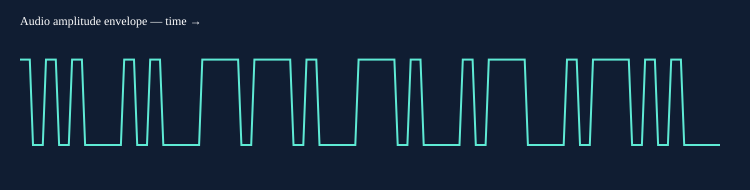

In [4]:
import wave, struct
from pathlib import Path
class SVG:
    def __init__(self, text): self.text=text
    def _repr_svg_(self): return self.text
    def __repr__(self): return "Audio amplitude envelope (SVG)"
audio_path = Path("signal_practice.wav")
if not audio_path.exists(): audio_path = Path("preparation/signal_practice.wav")
with wave.open(str(audio_path), "rb") as f:
    data = struct.unpack("<"+"h"*f.getnframes(), f.readframes(f.getnframes()))
step=160
peaks=[max(abs(x) for x in data[i:i+step])/32768 for i in range(0,len(data),step)]
points=" ".join(f"{20+i*700/max(1,len(peaks)-1):.1f},{145-p*200:.1f}" for i,p in enumerate(peaks))
SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="750" height="190"><rect width="750" height="190" fill="#101d32"/><text x="20" y="25" fill="white">Audio amplitude envelope — time →</text><polyline points="{points}" fill="none" stroke="#5eead4" stroke-width="2"/></svg>')

## Extra practice answers

1. `01000001` = 64 + 1 = 65 = `A`. The mapping was supplied; pitch alone does not define which tone means 1.
2. `[0, 2, 0, 2]`. A shared component cancels. This does not guarantee a useful result for arbitrary stereo audio; a message shared by both channels would also cancel.
3. Dash: 240 ms; letter gap: 240 ms; word gap: 560 ms; within-letter mark gap: 80 ms. A dash is sound, whereas a letter gap is silence.
4. `124`. Each digit uses both frequencies and the given lookup table.